### Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [61]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

# Step 2: Check actual files inside the folder
files = os.listdir(path)
print("Files in dataset folder:", files)

# Step 3: Load the correct CSV file
file_path = os.path.join(path, files[0])  # auto-pick CSV
data = pd.read_csv(file_path)

Files in dataset folder: ['amz_uk_price_prediction_dataset.csv']


In [62]:
df = data.copy()

In [63]:
print(df.head())

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [65]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [66]:
df.shape

(2443651, 9)

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [68]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1.370545e+06,816056.169852,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.152836e+00,2.194865,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,4.806278e+02,5944.124151,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,8.924381e+01,345.608862,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,2.589699e+01,240.483727,0.0,0.00,0.00,0.00,50000.0


In [69]:
df.describe(include="object").T

,count,unique,top,freq
asin,2443651,2222742,B07MVP6T9C,7
title,2443651,2077591,OYhmc Portable Pedal Exerc,723
category,2443651,296,Sports & Outdoors,836265


* **The dataset was divided into categorical and numerical variables to facilitate structured analysis. This allows appropriate methods to be applied depending on variable type, such as crosstab analysis for categorical variables and correlation analysis for numerical variables.**

In [70]:
cat = df.select_dtypes(exclude="number")
num = df.select_dtypes(include="number")

In [71]:
cat.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

#### I. CROSSTAB ANALYSIS

In [72]:
crosstab = pd.crosstab(cat['category'], cat['isBestSeller'])
crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [73]:
# Converting it to proportions

crosstab_prop = crosstab.div(crosstab.sum(axis=1), axis=0)
crosstab_prop = crosstab_prop.sort_values(by=True, ascending=False)
crosstab_prop.head(10)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


* INSIGHTS:
    - The analysis reveals that certain product categories have a higher proportion of best-sellers than others. Categories such as Grocery (5.81%), Smart Home Security & Lighting (5.77%), and Health & Personal Care (5.77%) exhibit the highest best-seller rates.
    - The crosstab analysis shows that categories such as Grocery, Smart Home Security & Lighting, and Health & Personal Care have the highest proportion of best-sellers (~5–6%). However, the overall proportion of best-sellers remains low across all categories, indicating that achieving best-seller status is relatively rare.
    - The variation across categories, while present, is moderate, suggesting that category alone does not strongly determine success.


#### II. STATISTICAL TESTS

##### A. Chi-Square Test (Independence Test)

In [74]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(crosstab)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


**The Hypothesis being asked:**
- H₀ (null hypothesis): Category and best-seller are independent
- H₁ (alternative): They are related

**For p-value:**

| p-value     | Meaning                  |
|------------|---------------------------|
| < 0.05     | Significant relationship  | 
| ≥ 0.05     | No relationship           |



* INSIGHT:
    - The Chi-square test was conducted to determine whether product category and best-seller status are independent. The resulting p-value is significantly below 0.05, indicating that there is a statistically significant relationship between category and best-seller status. Therefore, we reject the null hypothesis and conclude that product category influences the likelihood of being a best-seller.

##### B. Cramér’s V (Strength of Relationship)

In [75]:
n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))

print("Cramer's V:", cramers_v)

Cramer's V: 0.1222829439760564


In [76]:
# Alternatively using the association_metrics library

from scipy.stats.contingency import association

association(crosstab, method='cramer')


0.1222829439760564

#### Cramér’s V Interpretation Guide (Cohen's Conventions)

| Cramér’s V | Strength of Association   |
|------------|----------------------------|
| 0.00–0.10  | Negligible / Very Weak     |
| 0.10–0.20  | Weak                       |
| 0.20–0.30  | Moderate                   |
| 0.30–0.50  | Strong                     |
| > 0.50     | Very Strong                |

* INSIGHT
    - The Chi-square test indicates a statistically significant relationship between product category and best-seller status. However, Cramér’s V suggests that this relationship is weak, meaning that although category has some influence, it is not a strong predictor of success. This implies that other factors such as pricing, reviews, and competition likely play a more important role.

#### III. VISUALIZATION

* Let's first analyze all categories using Stacked Bar

<Figure size 1200x600 with 0 Axes>

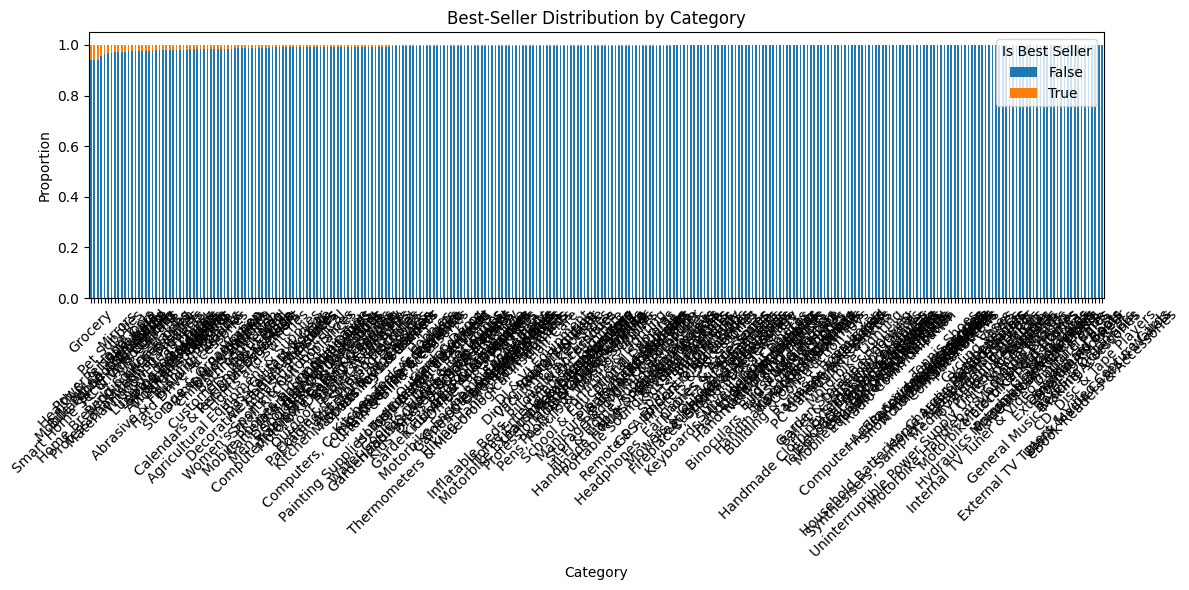

In [77]:
plt.figure(figsize=(12,6))

crosstab_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6)
)

plt.title("Best-Seller Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45)
plt.legend(title="Is Best Seller")
plt.tight_layout()

plt.show()

* Unreadable and uninterpretable figure due to too many categories being analyzed.

* Filtering to only the Top Categories (Top 10) by isBestSeller rate will provide us with a more robust figure to analyze:

In [45]:
top10_best = crosstab_prop.head(10)
top10_best

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


<Figure size 1000x600 with 0 Axes>

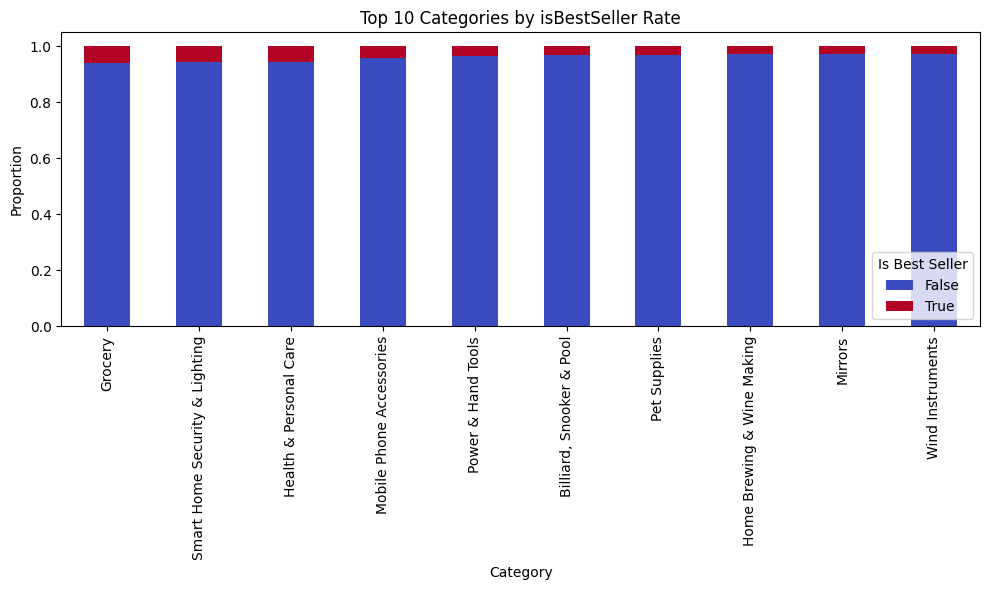

In [79]:
plt.figure(figsize=(10,6))

top10_best.plot(
    kind='bar',
    stacked=True,
    colormap='coolwarm',
    figsize=(10,6)
)

plt.title("Top 10 Categories by isBestSeller Rate")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=90)

plt.legend(title="Is Best Seller", loc='lower right', bbox_to_anchor=(1, 0))

plt.tight_layout()

plt.show()

* INSIGHT
    - The stacked bar chart confirms that even in top-performing categories, the proportion of best-sellers remains small. While some categories show relatively higher best-seller shares, the differences are not substantial, reinforcing that best-seller success is not heavily driven by category alone.

    - However, even among the top-performing categories, the proportion of best-sellers remains low (below 6%), indicating that achieving best-seller status is uncommon across all categories. This reinforces the earlier finding that while category influences success, it is not the sole determining factor.

    - The visualization confirms that differences across categories exist but are not extreme, suggesting that other variables such as pricing, reviews, and competition likely play a more significant role.


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

#### Preliminary Step: Outlier Detection and Treatment in the product prices.

In [81]:
# Computing for the IQR

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)


Q1: 9.99
Q3: 45.99
IQR: 36.0


In [82]:
# Defining the bounds for outliers

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -44.01
Upper Bound: 99.99000000000001


In [83]:
# Filtering the Dataset to Remove Outliers

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

In [84]:
print("Original shape:", df.shape)
print("After removing outliers:", df_no_outliers.shape)

Original shape: (2443651, 9)
After removing outliers: (2115963, 9)


* **Outliers in product prices were removed using the IQR method. Values below Q1 − 1.5×IQR and above Q3 + 1.5×IQR were excluded to reduce skewness and ensure more reliable statistical analysis.**

In [88]:
# Alternatively, we can define a function to remove outliers using IQR

def remove_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    return df[(df[col] >= lower) & (df[col] <= upper)]

In [89]:
df_no_outliers = remove_outliers_iqr(df, 'price')

In [90]:
print("Original shape:", df.shape)
print("After removing outliers:", df_no_outliers.shape)

Original shape: (2443651, 9)
After removing outliers: (2115963, 9)


* INSIGHT

    - The removal of outliers ensures that extreme price values do not distort the analysis, allowing for a more accurate representation of typical product pricing behavior.

#### I. Violin Plot (Price Distribution by Category)

In [91]:
# Getting the Top 20 categories by count

top20 = df_no_outliers['category'].value_counts().nlargest(20).index

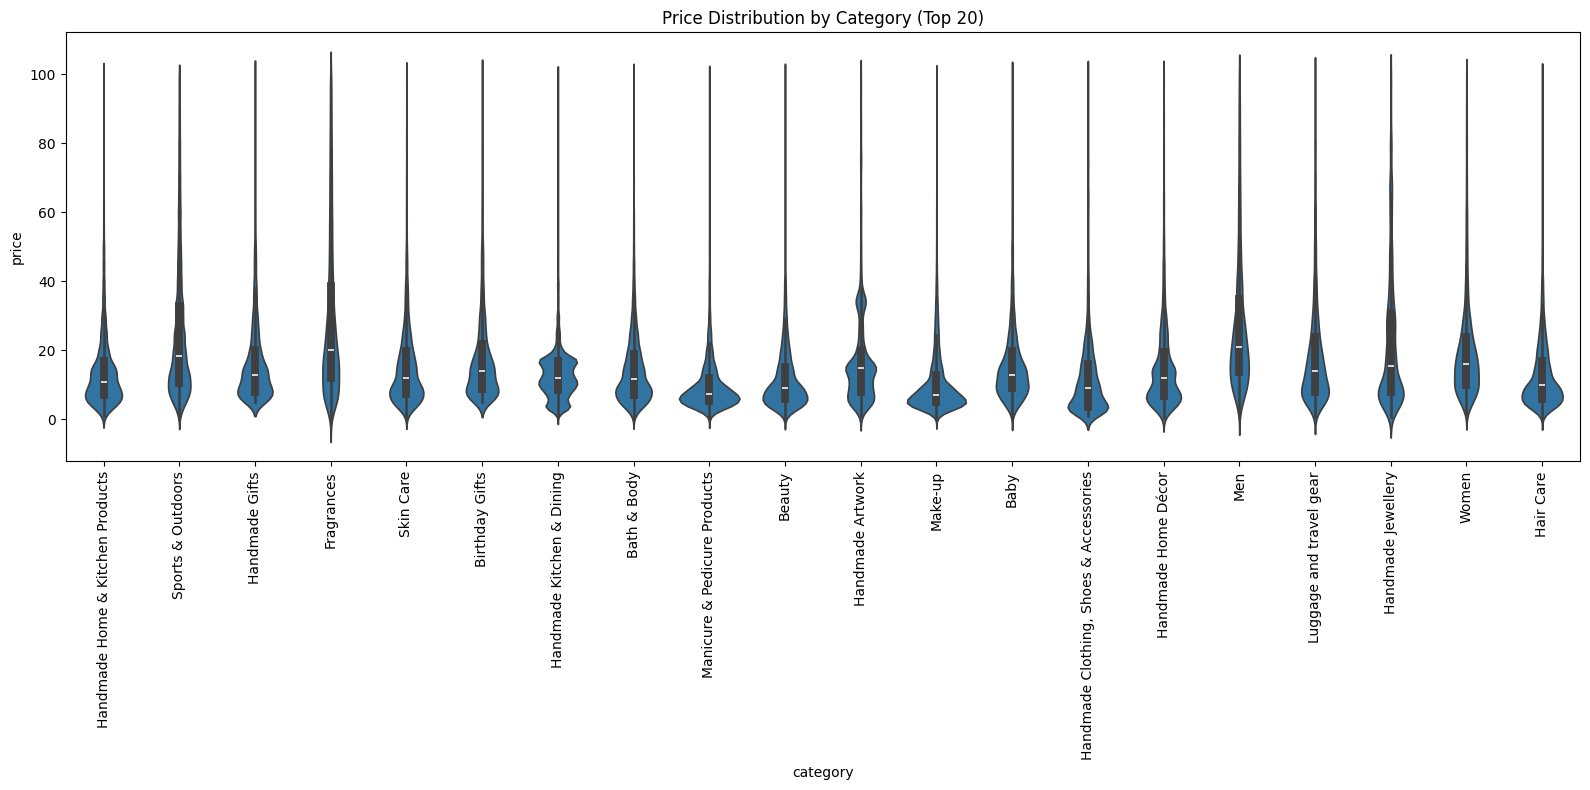

In [95]:
# Plotting the price distribution by category for the top 20 categories using a violin plot

plt.figure(figsize=(16,8))

sns.violinplot(
    data=df_no_outliers[df_no_outliers['category'].isin(top20)],
    x='category',
    y='price'
)

plt.title("Price Distribution by Category (Top 20)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [94]:
# The highest Median Price (No filtering)

df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

* INSIGHT

    - The violin plot reveals that price distributions vary significantly across categories, with some categories showing higher median prices and wider spreads. This indicates differences in pricing strategies and product positioning, with certain categories targeting more premium segments.

#### II. Bar Chart (Average Price)

In [96]:
# Calculating the Top 10 by count

top10 = df_no_outliers['category'].value_counts().nlargest(10).index


In [97]:
# Computing for the Average (Mean) Price for the Top 10 Categories

avg_price = df_no_outliers[df_no_outliers['category'].isin(top10)] \
    .groupby('category')['price'].mean().sort_values(ascending=False)

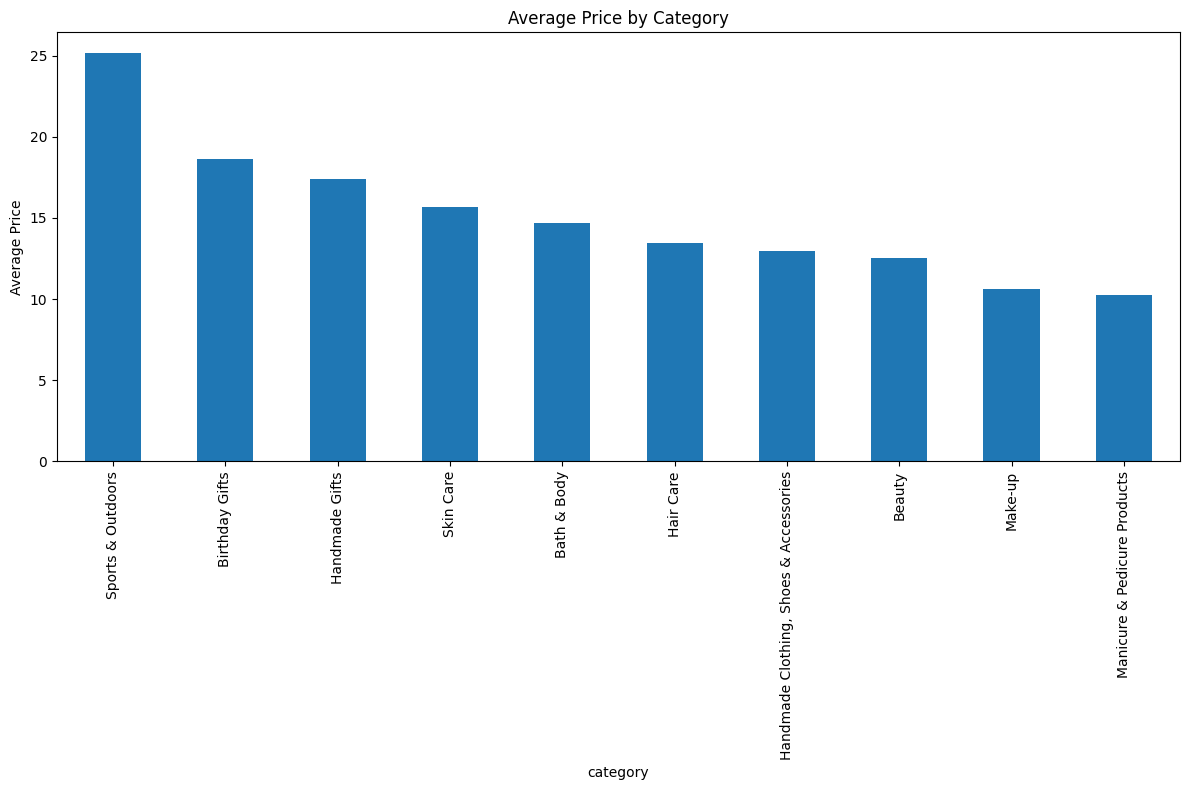

In [100]:
# Plotting using a bar plot

avg_price.plot(kind='bar', figsize=(12,8))

plt.title("Average Price by Category")
plt.xticks(rotation=90)
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()

In [101]:
# Computing for the Highest Average Price without filtering

df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False).head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

* Insight

    - Certain categories command higher average prices, indicating premium segments or higher-value products.

    - The difference between mean and median prices across categories suggests the presence of skewness, where a small number of high-priced products inflate the average.

#### III. Box Plot (Ratings by Category)

In [102]:
# Computing for the Top 10

top10 = df_no_outliers['category'].value_counts().nlargest(10).index

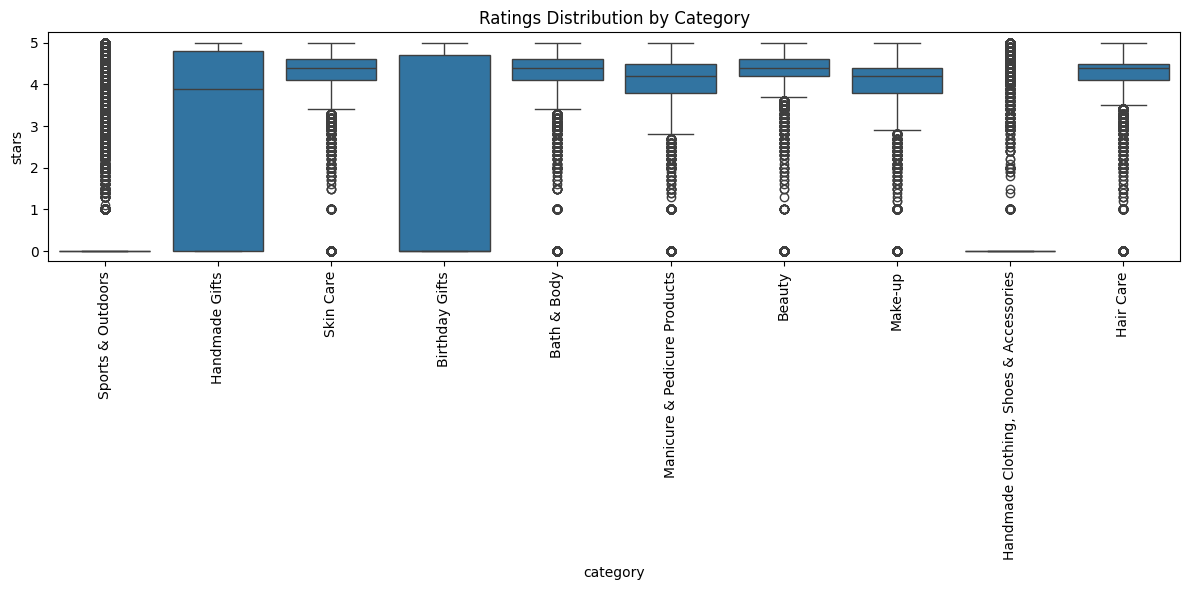

In [104]:
# Plotting using Box Plot for the Top 10 Categories

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df_no_outliers[df_no_outliers['category'].isin(top10)],
    x='category',
    y='stars'
)

plt.title("Ratings Distribution by Category")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

* **NOTE: The dataset uses the column stars to represent product ratings, which corresponds to the rating variable mentioned in the lab instructions.**

In [105]:
# Computing for the Highest Median Rating without filtering

df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False).head(10)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

* INSIGHT

    - Most categories have high ratings overall, but slight differences in median ratings suggest varying levels of customer satisfaction across categories.

    - Ratings are highly concentrated between 4 and 5 stars across all categories, indicating limited variability. This compression reduces the ability to detect strong differences between categories.

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

### Part 3: Investigating the Interplay Between Product Prices and Ratings

#### I. CORRELATION COEFFICIENTS (BETWEEN PRICE AND STARS)

In [106]:
# Using the clean data without outliers

df_no_outliers[['price', 'stars']].corr()

,price,stars
price,1.000000,-0.077673
stars,-0.077673,1.000000


**Interpreting the Correlation Coefficients**

| Value      | Meaning          |
|------------|------------------|
| ~ 0        | No relationship  | 
|   +        | Positve          |
|   -        | Negative         |

* INSIGHT

    - The correlation coefficient (-0.077) indicates a very weak negative relationship between price and ratings. This suggests that price has virtually no influence on customer ratings, and higher-priced products are not necessarily perceived as better by customers.

#### II. VISUALIZATION

#### A. SCATTER PLOT

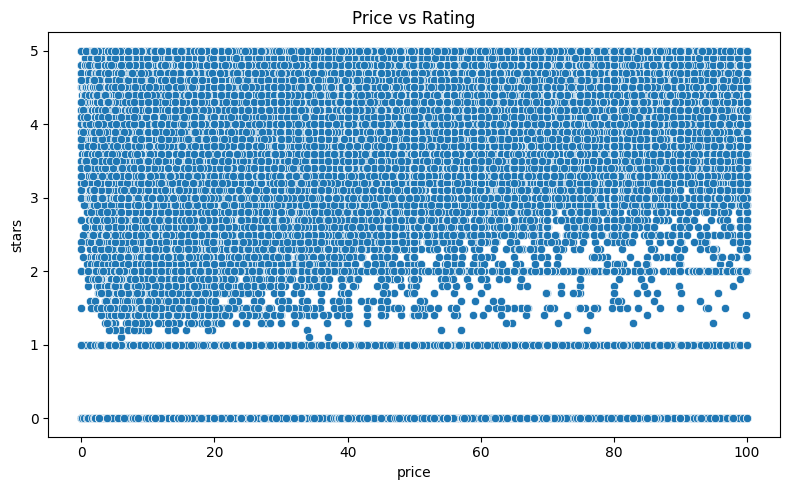

In [107]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_no_outliers,
    x='price',
    y='stars'
)

plt.title("Price vs Rating")
plt.tight_layout()
plt.show()

* INSIGHT

    - The scatter plot shows no clear relationship between price and ratings. Most products, regardless of price, tend to have high ratings, suggesting that customer satisfaction is not strongly influenced by price.

    - Ratings (stars) are compressed at the upper end (4–5 stars), limiting variability and reducing observable correlation.

    - The scatter plot shows a wide dispersion of ratings across all price levels, with most ratings clustered between 4 and 5 stars. This reinforces the lack of a clear relationship between price and customer satisfaction.

#### B. CORRELATION HEATMAP

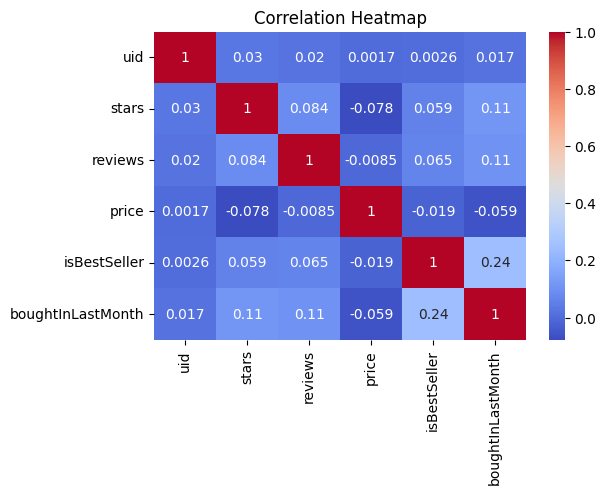

In [108]:
plt.figure(figsize=(6,4))

sns.heatmap(
    df_no_outliers.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

* INSIGHT

    - The correlation heatmap confirms that there are no strong linear relationships between price and other numerical variables, reinforcing the conclusion that price is not a dominant factor influencing ratings.

#### C. QQ PLOT (NORMALITY CHECK)

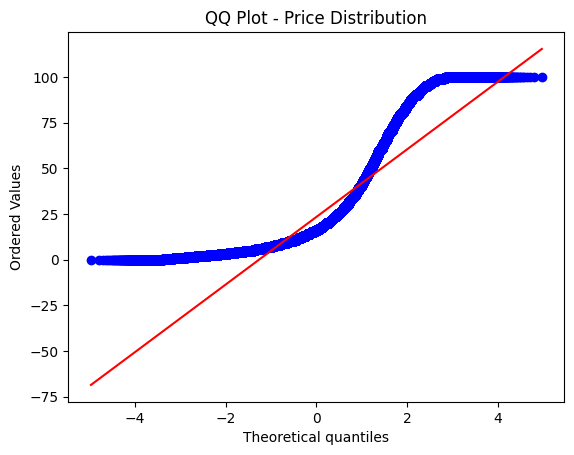

In [109]:
import scipy.stats as stats

stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)

plt.title("QQ Plot - Price Distribution")
plt.show()

**Interpreting the Shape**

| Shape         | Meaning              |
|---------------|----------------------|
| Straight Line | Normal Distribution  | 
| Curved        | Skewed               |


* INSIGHT

    - The QQ plot shows a clear deviation from the normal distribution, with an S-shaped pattern indicating right skewness. This suggests that most products are priced at lower ranges, with fewer high-priced items. The flattening at the upper end may reflect the impact of outlier removal or natural price limits.

# **SUMMARY REPORT**

### OBJECTIVE

- The objective of this analysis is to explore product pricing, category dynamics, and customer ratings in the Amazon UK dataset. The goal is to identify patterns that influence best-seller status, pricing strategies, and customer satisfaction.

### BEST-SELLER TRENDS ACROSS CATEGORIES

**Key Findings**

* Categories such as Grocery, Smart Home Security & Lighting, and Health & Personal Care show the highest proportion of best-sellers (~5–6%).

* However, best-seller products remain rare across all categories, with over 94% of products not achieving this status.

* The Chi-square test confirms a statistically significant relationship between category and best-seller status.

* However, Cramér’s V indicates a weak association, meaning category alone is not a strong predictor of success.



**Business Insight**

* While product category influences the likelihood of becoming a best-seller, it is not sufficient on its own. Other factors such as reviews, pricing, and competition likely play a more significant role.

### PRODUCT PRICING ACROSS CATEGORIES

**Key Findings**

* Price distributions vary significantly across categories.

* Some categories exhibit higher median and average prices, indicating premium segments.

* The price distribution is right-skewed, meaning most products are low-priced with a few high-priced items.

* Outliers were removed using the IQR method to ensure more reliable analysis.

**Business Insight**

* Pricing strategies differ by category, reflecting varying levels of product value and market positioning. Median price is a more reliable metric than mean due to skewness.

### PRODUCT RATING (STARS) ACROSS CATEGORIES

**Key Findings**

* Most products across all categories have high ratings (typically 4–5 stars).

* Differences in median ratings across categories are relatively small.

* Customer satisfaction appears to be consistently high regardless of category.

**Business Insight**

* Ratings are generally high across all categories, suggesting that customer satisfaction is widespread and not strongly dependent on product category alone.

### RELATIONSHIP BETWEEN PRICE AND RATING

**Key Findings**

* The correlation between price and ratings is very weak (-0.077).

* Scatter plot analysis shows no clear relationship between price and customer ratings.

* The QQ plot confirms that price is not normally distributed and is right-skewed. 


**Business Insight**

* Higher-priced products are not necessarily better rated. Customer satisfaction is influenced more by perceived value, product quality, and user experience rather than price alone.

### CONCLUSION

* This analysis reveals that while category and pricing influence product dynamics, they are not strong standalone predictors of success or customer satisfaction. Best-seller status is rare and likely driven by a combination of factors including demand, competition, and product differentiation. Additionally, the weak relationship between price and ratings suggests that businesses should focus on delivering value rather than relying solely on premium pricing strategies.

* Overall, the analysis suggests that success on Amazon is multifactorial. While category and pricing influence product dynamics, they are not strong standalone predictors of best-seller status or customer satisfaction.

* Businesses should prioritize value delivery, customer experience, and competitive positioning rather than relying solely on category selection or pricing strategies.

### RECOMMENDATIONS

* Focus on high-performing categories with better best-seller probabilities.

* Use median price for decision-making due to skewed distributions.

* Prioritize customer experience and product quality over pricing alone.

* Avoid oversaturated categories unless strong differentiation exists.
